# Практикалық жұмыс 5. Сызықты регрессия.

Бұл практикалық жұмыста `Scikit-Learn` кітапханасының көмегімен сызықтық регрессияны жүзеге асыру кезең-кезеңімен түсіндіріледі.

Практикалық жұмыста қолданылатын деректер жиынын автордың GitHub репозиторийінен жүктеп алуға болады.

**Мақсаты:**

- сызықтық регрессия моделін құру;
- модельді оқыту;
- болжам жасау;
- модельдің сапасын бағалау.







## 1. Қажетті кітапханаларды жүктеу

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt

### 2. Датасетті дисктен жүктеу
Егер 'ex1data1.txt' файлы Google Drive-та болса, келесі кодты орындап ашасыз:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Файлды басқа да жолмен ашуға болады, мұнда тікелей қолда бар txt файлды ашамыз:

In [ ]:
df = pd.read_csv('ex1data1.txt', names=['x', 'y'])
df.head()

,x,y
0,6.1101,17.5920
1,5.5277,9.1302
2,8.5186,13.6620
3,7.0032,11.8540
4,5.8598,6.8233


### 3. Датасетті `df_tips` айнымалысына сақтау

1. Әдепкі жағдайда `pd.read_csv()` файлдағы деректер үтірмен бөлінген деп есептейді. Сондықтан CSV файлын оқу кезінде `delimiter=','` параметрін арнайы көрсетудің қажеті жоқ.

   Егер файлдағы мәндер басқа таңбамен, мысалы, табуляциямен бөлінсе, бөлу таңбасын `delimiter` параметрі арқылы көрсетуге болады.

2. `names=['X', 'Y']` — CSV файлындағы бағандарға атау береді:

   - бірінші баған — `X`;
   - екінші баған — `Y`.

```python
df_tips = pd.read_csv(
    "файл_жолы.csv",
    names=["X", "Y"]
)
```

Мұнда `names` параметрі Pandas-қа алынған `DataFrame` бағандарын `X` және `Y` деп атау керектігін көрсетеді.

Егер CSV файлында баған атаулары бұрыннан бар болса, `names` параметрін жазудың қажеті жоқ. Әйтпесе файлдағы тақырып жолы да қарапайым дерек ретінде оқылып кетуі мүмкін.

# Бір айнымалысы бар сызықтық модельді құру

## 3-қадам. Деректерді оқыту (train) және тестілеу(test) жиындарына бөлу

In [ ]:
X = df[['x']]
y = df[['y']]
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       101 non-null    float64
dtypes: float64(1)
memory usage: 940.0 bytes


In [ ]:
y.info()

<class 'pandas.core.series.Series'>
RangeIndex: 97 entries, 0 to 96
Series name: y
Non-Null Count  Dtype  
--------------  -----  
97 non-null     float64
dtypes: float64(1)
memory usage: 904.0 bytes


Шығарылған нәтиже `X` және `y` деп аталатын екі `Series` туралы ақпарат береді.

1. **`<class 'pandas.core.series.Series'>`**  
   `X` және `y` объектілерінің екеуі де Pandas кітапханасындағы `Series` түріне жатады.

2. **`RangeIndex: 97 entries, 0 to 96`**  
   Әрбір `Series` ішінде 97 жол бар. Олардың индекстері 0-ден басталып, 96-ға дейін жалғасады.

3. **`Series name: x` — `X` үшін**  
   `X` сериясының атауы — `x`. Бұл оның бастапқы `df` кестесіндегі баған атауына сәйкес келеді.

   **`Series name: y` — `y` үшін**  
   Сол сияқты, `y` сериясының атауы — `y`.

4. **`Non-Null Count`**  
   Екі серияда да бос емес 97 мән бар. Демек, `X` және `y` бағандарында бос немесе `NaN` мәндер жоқ.

5. **`Dtype: float64`**  
   Екі сериядағы мәндер де ондық сандар түрінде сақталған.

6. **`memory usage: 904.0 bytes`**  
   Әрбір серия компьютер жадында 904 байт орын алады.

Қысқаша айтқанда, код `df` кестесінен `x` және `y` бағандарын жеке алып, `info()` әдісі арқылы олар туралы ақпаратты тексереді. Екі бағанда да бос мәндер жоқ және әрқайсысында 97 ондық сан сақталған.

Деректер жиынын оқыту және тестілеу бөліктеріне бөлу үшін `Scikit-Learn` кітапханасының `model_selection` модуліндегі `train_test_split` функциясын қолданамыз.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

## Step 4. Plot the Train Data as Scatter Plot

In [ ]:
X_train

,x
40,6.3316
72,5.7292
9,5.7077
96,9.0837
11,5.0546
...,...
60,7.3695
71,5.5204
14,6.7113
92,19.2270


## 4. Оқыту деректерін нүктелік диаграммада көрсету

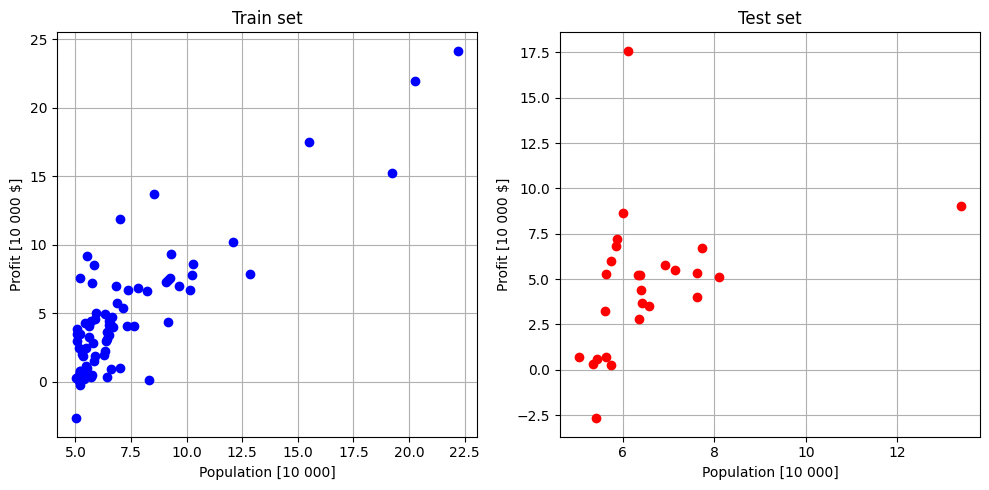

In [ ]:
plt.figure(figsize=(10, 5))

# Сол жақтағы график — оқыту деректері
plt.subplot(1, 2, 1)
plt.plot(X_train, y_train, "ob")  # o — нүкте, b — көк түс
plt.xlabel("Population [10 000]")
plt.ylabel("Profit [10 000 $]")
plt.grid()
plt.title("Train set")

# Оң жақтағы график — тест деректері
plt.subplot(1, 2, 2)
plt.plot(X_test, y_test, "or")  # o — нүкте, r — қызыл түс
plt.xlabel("Population [10 000]")
plt.ylabel("Profit [10 000 $]")
plt.grid()
plt.title("Test set")

plt.tight_layout()
plt.show()

## 5. Сызықты регрессия (linear regression, LR) моделін оқыту

```python
lr_model.fit(np.array(X_train).reshape(-1, 1), y_train)
```

1. `X_train` сериясын NumPy массивіне түрлендіреміз. Мұндай пішінге өзгерту себебі — `Scikit-Learn` кіріс белгілері `X` екі өлшемді массив, яғни матрица түрінде болуын талап етеді. Мұнда әрбір баған — бір белгі, ал әрбір жол — бір бақылау.

2. `.reshape()`

- `.reshape()` — массивтің пішінін өзгертуге арналған әдіс.
- Бірінші аргумент `-1` жолдар саны массивтің өлшеміне және көрсетілген бағандар санына қарай автоматты түрде анықталатынын білдіреді.
- Екінші аргумент `1` алынған массивте бір ғана баған болатынын көрсетеді.

In [ ]:
X_train

,x
40,6.3316
72,5.7292
9,5.7077
96,9.0837
11,5.0546
...,...
60,7.3695
71,5.5204
14,6.7113
92,19.2270


In [ ]:
y_train

,y
40,2.20330
72,0.47953
9,4.38870
96,7.26960
11,3.81660
...,...
60,6.67180
71,1.00060
14,4.00410
92,15.22700


In [ ]:
# Сызықтық регрессия моделін импорттау
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()

# Сызықтық регрессия моделін оқыту
lr_model.fit(np.array(X_train).reshape(-1, 1), y_train)

print(
    "Модель: {0} + {1}*x".format(
        lr_model.intercept_,
        lr_model.coef_[0]
    )
)

# Модельді тест жиынында бағалау
# lr_model.score(X_test, y_test)

Модель: [-3.92667565] + [1.20030753]*x


Бұл код LR моделін құрып, оқытады және табылған теңдеуді көрсетеді.

```python
from sklearn.linear_model import LinearRegression
```

`Scikit-Learn` кітапханасынан сызықтық регрессия класын импорттайды.

```python
lr_model = LinearRegression()
```

Бос сызықтық регрессия моделін жасайды. Бұл кезде модель әлі оқытылған жоқ.

```python
lr_model.fit(np.array(X_train).reshape(-1, 1), y_train)
```

Модельді оқыту деректерімен үйретеді:

- `X_train` — кіріс мәндері, яғни қала халқы;
- `y_train` — нақты жауаптар, яғни пайда;
- `np.array()` — `X_train` мәндерін NumPy массивіне айналдырады;
- `reshape(-1, 1)` — массивті бір бағанды кестеге түрлендіреді;
- `fit()` — \(X\) пен \(y\) арасындағы ең қолайлы сызықтық байланысты табады.

Модельдің формуласы:
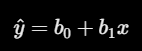


Келесі код осы теңдеуді экранға шығарады:

```python
print("model is: {0} + {1}*x".format(
    lr_model.intercept_,
    lr_model.coef_[0]
))
```

- `lr_model.intercept_` — \(b_0\), бос мүше;
- `lr_model.coef_[0]` — \(b_1\), \(x\)-тің коэффициенті.

Мысалы, нәтиже:

```text
model is: -4.5 + 1.2*x
```

болса, модель теңдеуі:

\[
 y=-4.5+1.2x
\]

Бұл \(x\) бір бірлікке артқанда, болжамды \(y\) орта есеппен **1,2 бірлікке өседі** дегенді білдіреді.

```python
# lr_model.score(X_test, y_test)
```

Бұл жол тест деректерінде модельдің \(R^2\) көрсеткішін есептейді. Бірақ басында `#` тұрғандықтан, код орындалмайды. Іске қосу үшін:

```python
print(lr_model.score(X_test, y_test))
```

деп жазыңыз. \(R^2\) мәні 1-ге жақын болған сайын модель деректерді жақсырақ түсіндіреді.

- Сызықтық регрессия моделін оқытқаннан кейін, ол `X_train` мен `y_train` арасындағы байланысты сипаттайтын ең қолайлы параметрлерді — бос мүше мен коэффициентті анықтайды.

- `lr_model.intercept_` — сызықтық регрессия теңдеуіндегі бос мүше, яғни \(y\) осімен қиылысу нүктесі. Ол барлық кіріс белгілері \(X=0\) болған кездегі \(y\) мақсатты айнымалысының болжамды мәнін көрсетеді.

- `lr_model.coef_` — әрбір белгіге сәйкес коэффициенттер массивін қайтарады. Бізде бір ғана белгі бар қарапайым сызықтық регрессия қолданылғандықтан, сол белгінің коэффициентін алу үшін `lr_model.coef_[0]` жазамыз. Бұл коэффициент кіріс белгісі бір бірлікке өзгерген кезде мақсатты айнымалының қаншаға өзгеретінін көрсетеді.

## 6. Модельді болжам сызығымен бірге графикте көрсету

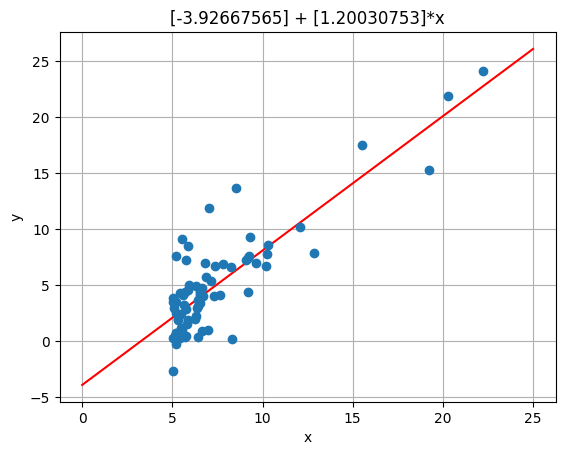

In [ ]:
# define x value (0,25)
x_plot = np.linspace(0,25 , 2)            # 2 data points between 0 ~ 25
x_plot = x_plot.reshape(-1, 1)             # preprocessing required by scikit-learn functions

# болжам
y_plot = lr_model.predict(x_plot)

# Нәтижелер
plt.figure()
plt.plot(x_plot,y_plot,'r')
plt.plot(X_train,y_train,'o')
plt.title("{0} + {1}*x".format(lr_model.intercept_,lr_model.coef_[0]))
plt.xlabel('x')
plt.ylabel('y')
plt.grid()

# Көк нүктелер — нақты деректер, яғни әрбір x-ке сәйкес нақты y мәндері.
# Қызыл сызық — сызықтық регрессия моделінің болжам сызығы.

Бұл графикке қарап, модель деректерге қанағаттанарлық деңгейде сәйкес келеді деп айтуға болады. Егер сызық барлық дерек нүктелерінің төменгі жағында орналасса, бұл модельде кілтипан болуы мүмкін екенін көрсетер еді.

## 7. Оқыту жиыны (train set) үшін болжам жасап, модель қатесін бағалау

In [ ]:
# Оқыту жиыны үшін болжам жасау
y_train_pred = lr_model.predict(
    np.array(X_train).reshape(-1, 1)) # массивті бір бағанды кестеге айналдырады, -1 — бірнеше жол, 1 — бір баған

# Нақты және болжанған мәндерден DataFrame құру
df_train = pd.DataFrame({
    "X_train": X_train.squeeze(), # .squeeze() бір бағанды қарапайым бір өлшемді қатарға айналдырады. Бұл мәндерді DataFrame ішіне дұрыс орналастыру үшін қолданылады.
    "y_train": y_train.squeeze(),
    "y_train_pred": y_train_pred.squeeze()
}).reset_index(drop=True)

# Кестенің алғашқы 10 жолын көрсету
df_train.head(10)

,X_train,y_train,y_train_pred
0,6.3316,2.20330,3.673192
1,5.7292,0.47953,2.950126
2,5.7077,4.38870,2.924320
3,9.0837,7.26960,6.976558
4,5.0546,3.81660,2.140399
5,15.5010,17.47000,14.679291
6,6.3105,4.92160,3.647865
7,5.3054,1.98690,2.441436
8,6.5232,4.45700,3.903170
9,6.4273,0.32594,3.788061


In [ ]:
# Шығын функциясының мәнін есептеу
train_cost = sum(abs(df_train['y_train'] - df_train['y_train_pred'])**2)/(2*df_train.shape[0])
print('------------------------------')
print('train_cost = {0}'.format(train_cost))
print('------------------------------')

------------------------------
train_cost = 3.149700010268262
------------------------------


In [ ]:
df_train

,X_train,y_train,y_train_pred
0,6.3316,2.20330,3.673192
1,5.7292,0.47953,2.950126
2,5.7077,4.38870,2.924320
3,9.0837,7.26960,6.976558
4,5.0546,3.81660,2.140399
...,...,...,...
70,7.3695,6.67180,4.918991
71,5.5204,1.00060,2.699502
72,6.7113,4.00410,4.128948
73,19.2270,15.22700,19.151637


## Тест жиыны үшін болжам жасап, модель қатесін бағалау

------------------------------
test_cost = 6.695863863875467
------------------------------


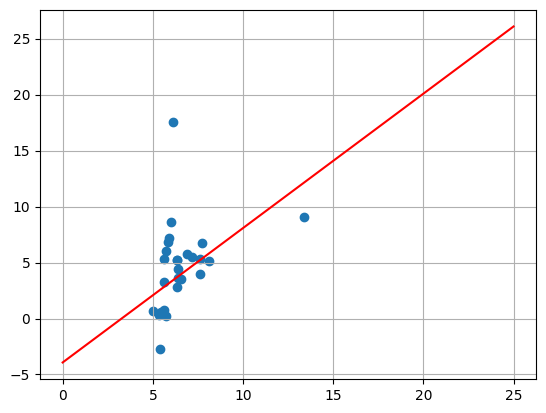

In [ ]:
y_test_pred = lr_model.predict(np.array(X_test).reshape(-1, 1))

# define a data frame with predictions and labels
df_test = pd.DataFrame({'x_test':X_test.squeeze(),'y_test':y_test.squeeze(),'y_test_pred':y_test_pred.squeeze()}).reset_index(drop=True)
df_test.head(10)

# calculate cost
test_cost = sum(abs(df_test['y_test'] - df_test['y_test_pred'])**2)/(2*df_test.shape[0])
print('------------------------------')
print('test_cost = {0}'.format(test_cost))
print('------------------------------')


plt.figure()
plt.scatter(df_test['x_test'], df_test['y_test'])
plt.plot(x_plot,y_plot,'r')
plt.grid()

Оқыту кезеңінде `train_cost` мәні **3.8559** болды. Бұл мәннің үлкен немесе қолайлы екенін анықтау үшін деректердің өлшем бірлігі мен ерекшеліктерін ескеру қажет.

Тестілеу кезеңінде `test_cost` мәні **6.5459** болды. Тест және оқыту деректері ұқсас көрінгенімен, тест қатесі оқыту қатесінен шамамен **1,7 есе жоғары**.

Бұл модельдің жаңа деректерде оқыту деректеріне қарағанда нашар жұмыс істейтінін көрсетеді. Бұған:

- деректер санының аз болуы;
- train және test жиындарының айырмашылығы;
- кездейсоқ шу;
- модельдің оқыту деректеріне артық бейімделуі

себеп болуы мүмкін.

Ескерту: тест қатесінің жоғары болуы міндетті түрде **жеткіліксіз үйренуді (underfitting)** білдірмейді. Underfitting кезінде әдетте оқыту және тест қателерінің екеуі де жоғары болады. Ал оқыту қатесі төмен, тест қатесі жоғары болса, бұл көбіне **қайта үйренудің (overfitting)** белгісі.

# 2) Екінші дәрежелі полином



Немесе толық атауы:

# Екінші дәрежелі полиномдық регрессия

Формуласы:
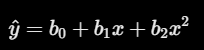

df деректер кестесінде x2 деп аталатын жаңа баған құрыңыз. Бұл бағанда x бағанындағы мәндердің квадраттары сақталады.

In [ ]:
df = pd.read_csv(path,names= ['x','y'])
df['x2'] = df['x'].pow(2)
df.head()

,x,y,x2
0,6.1101,17.5920,37.333322
1,5.5277,9.1302,30.555467
2,8.5186,13.6620,72.566546
3,7.0032,11.8540,49.044810
4,5.8598,6.8233,34.337256


Кестедегі бағандардың орналасу ретін өзгертеміз

In [ ]:
df[['x','x2', 'y' ]]

,x,x2,y
0,6.1101,37.333322,17.5920
1,5.5277,30.555467,9.1302
2,8.5186,72.566546,13.6620
3,7.0032,49.044810,11.8540
4,5.8598,34.337256,6.8233
...,...,...,...
96,9.0837,82.513606,7.2696
97,5.8707,34.465118,7.2029
98,5.4929,30.171950,1.1577
99,22.2030,492.973209,24.1470


In [ ]:
from sklearn.model_selection import train_test_split

X = df[['x','x2']]
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [ ]:
X_train

,x,x2
40,6.3316,40.089159
72,5.7292,32.823733
9,5.7077,32.577839
96,9.0837,82.513606
11,5.0546,25.548981
...,...,...
60,7.3695,54.309530
71,5.5204,30.474816
14,6.7113,45.041548
92,19.2270,369.677529


In [ ]:
y_train

,y
40,2.20330
72,0.47953
9,4.38870
96,7.26960
11,3.81660
...,...
60,6.67180
71,1.00060
14,4.00410
92,15.22700


In [ ]:
# import linear regression value
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()

# train the lr model
lr_model.fit(np.array(X_train).reshape(-1, 2),y_train) # 2 becouse we want reshape for 2 variables x and  x2


print("model is: {0} + {1}*x + {2}*x^2".format(lr_model.intercept_,lr_model.coef_[0],lr_model.coef_[1]))


# evaluate on test set
# lr.score(X_test, y_test)

model is: -3.69750410707642 + 1.1509565748336157*x + 0.002059959345331048*x^2


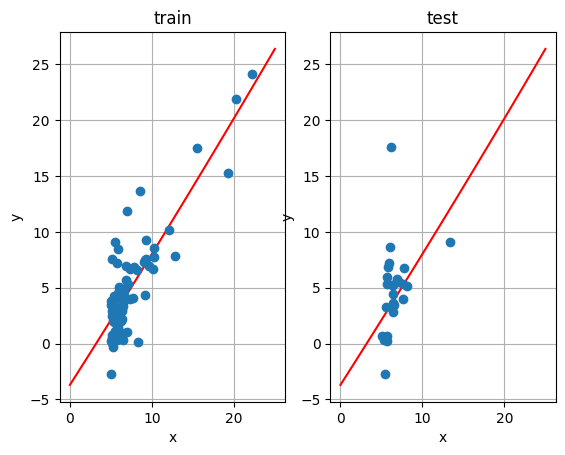

In [ ]:
# define x value (0, 25)
x_plot = np.linspace(0,25 , 100)            # 100 data points between 0 ~ 25
y_plot = lr_model.intercept_ + x_plot*lr_model.coef_[0] + lr_model.coef_[1]*np.power(x_plot,2)


# plot the results

plt.figure()
plt.subplot(1,2,1)
plt.plot(x_plot,y_plot,'r')
plt.plot(X_train['x'],y_train,'o')
plt.title('train')
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.subplot(1,2,2)
plt.plot(x_plot,y_plot,'r')
plt.plot(X_test['x'],y_test,'o')
plt.title('test')
plt.xlabel('x')
plt.ylabel('y')
plt.grid()

In [ ]:
y_train_pred = lr_model.predict(X_train)

# define a data frame with predictions and labels
df_test = pd.DataFrame({'x_test':X_train['x'].values,'y_train':y_train,'y_train_pred':y_train_pred}).reset_index(drop=True)
df_test.head(10)

# calculate cost
test_cost = sum(abs(df_test['y_train'] - df_test['y_train_pred'])**2)/(2*df_test.shape[0])
print('------------------------------')
print('train_cost = {0}'.format(test_cost))
print('------------------------------')


------------------------------
train_cost = 3.14907684030696
------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


In [ ]:
y_test_pred = lr_model.predict(X_test)

# define a data frame with predictions and labels
df_test = pd.DataFrame({'x_test':X_test['x'].values,'y_test':y_test,'y_test_pred':y_test_pred}).reset_index(drop=True)
df_test.head(10)

# calculate cost
test_cost = sum(abs(df_test['y_test'] - df_test['y_test_pred'])**2)/(2*df_test.shape[0])
print('------------------------------')
print('test_cost = {0}'.format(test_cost))
print('------------------------------')


# plt.figure()
# plt.scatter(df_test['x_test'],df_test['y_test'])
# plt.plot(x_plot,y_plot,'r')
# plt.grid()


------------------------------
test_cost = 6.691622242444985
------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


Бірінші дәрежелі модель үшін `train_cost` мәні **3,85**, ал екінші дәрежелі модель үшін **3,84** болды. Айырмашылық өте аз, сондықтан бұл деректер үшін қарапайым бірінші дәрежелі сызықтық модель жеткілікті.

Екі модельдің `test_cost` мәндері де шамамен бірдей болды. Демек, модельге \(x^2\) белгісін қосу болжам сапасын айтарлықтай жақсартпады. Сол себепті түсіндірілуі оңай және қарапайым бірінші дәрежелі модельді таңдаған дұрыс.



---



# ТАПСЫРМА

# **Мақсаты:** қала халқының саны бойынша кәсіпорынның пайдасын болжайтын сызықтық регрессия моделін құру.

### Тапсырмалар

1. `ex1data1.txt` файлын `Pandas` көмегімен жүктеңіз. Бағандарды:

   - `population`;
   - `profit`

   деп атаңыз.

2. Деректер туралы бастапқы ақпаратты шығарыңыз:

```python
df.head()
df.info()
df.describe()
df.isnull().sum()
```

3. `population` мен `profit` арасындағы байланысты нүктелік диаграммада көрсетіңіз.

4. Деректерді белгілер мен мақсатты айнымалыға бөліңіз:

```python
X = df[["population"]]
y = df["profit"]
```

5. Деректерді 75% оқыту және 25% тест жиынына бөліңіз. `random_state=42` қолданыңыз.

6. `LinearRegression` моделін құрып, оқыту жиынында үйретіңіз.

7. Модельдің теңдеуі қандай болады? Коэффициент пен бос мүшенің мағынасын түсіндіріңіз.

8. Оқыту және тест жиындары үшін болжам жасаңыз.

9. Нақты және болжанған мәндерден кесте құрыңыз:

| population | Нақты пайда | Болжанған пайда | Қате |
|---:|---:|---:|---:|

10. Модельді келесі метрикалармен бағалаңыз:

- MAE;
- MSE;
- RMSE;
- \(R^2\).

11. Нақты нүктелер мен регрессия сызығын бір графикте көрсетіңіз.

12. Халқы төмендегі мәндерге тең қалалар үшін пайданы болжаңыз:

```python
new_population = [[7], [12], [18]]
```

13. Екінші дәрежелі полиномдық модель құрыңыз:

14. Сызықтық және полиномдық модельдердің тест нәтижелерін салыстырыңыз:

| Модель | MAE | RMSE | \(R^2\) |
|---|---:|---:|---:|
| Сызықтық |  |  |  |
| Полиномдық |  |  |  |

15. Қай модель тиімді екенін 3–5 сөйлеммен қорытындылаңыз.

### Бақылау сұрақтары

1. `X` пен `y` нені білдіреді?
2. Деректерді неге `train` және `test` бөліктеріне бөлеміз?
3. `fit()` және `predict()` әдістерінің айырмашылығы қандай?
4. \(R^2\) мәні 1-ге жақындаса, ол нені білдіреді?
5. Неліктен тек оқыту қатесіне қарап модельді бағалауға болмайды?
6. Екінші дәрежелі модель қай кезде қажет?


### Бағалау критерийі

- Деректерді жүктеу және тексеру — 10 балл
- Визуализация — 10 балл
- Деректерді бөлу және модельді оқыту — 20 балл
- Болжам жасау — 15 балл
- Метрикаларды есептеу — 20 балл
- Екі модельді салыстыру — 15 балл
- Қорытынды мен кодтың рәсімделуі — 10 балл

**Барлығы: 100 балл.**